# Tau-5$_{R2}$ dissociation and association kinetics

Generate the four-panel SI Figure S2 from the binary dimer self-association time series. The saved outputs below were executed with the user-provided **r1r2 trajectories and the confirmed 0.24-ns frame interval**.

**To rerun with the full trajectories:** edit the next cell's trajectory/topology filenames and `FRAME_INTERVAL_NS` using the verified saved-frame interval, then **Restart Kernel and Run All**. No frame interval or total simulation length is inferred from filenames or DCD timestamps. Use coordinates whose periodic boxes and atom order match their topology.

Dependencies: Python, NumPy, SciPy, Matplotlib, MDTraj, and IPython. If needed, install them in your notebook environment with `%pip install numpy scipy matplotlib mdtraj ipykernel`.

Extract the full-resolution `r1r2.zip` archive alongside this notebook, or change `DATA_DIR`. This archive was supplied separately; the repository README links older downsampled coordinates. All generated files go into `OUTPUT_DIR`; input coordinates and manuscript files are never modified.

In [1]:
from pathlib import Path

# EDIT THIS CELL when switching to verified full-resolution coordinates.
DATA_DIR = Path("r1r2")
OUTPUT_DIR = Path("outputs/dissociation_kinetics")
FRAME_INTERVAL_NS = 0.24  # Saved-frame interval confirmed by the trajectory provider.
SYSTEMS = [
    dict(name="Apo", trajectory="apo/protein.100us.dcd",
         topology="epi002/R2_dimer.pdb", color="#BB383B"),
    dict(name="EPI-002", trajectory="epi002/protein.100us.dcd",
         topology="epi002/R2_dimer.pdb", color="#3475AD"),
    dict(name="1aa", trajectory="cam1/protein.85us.dcd",
         topology="epi002/R2_dimer.pdb", color="#43863B"),
]
# For protein+ligand files, set the corresponding matching protein+ligand PDB above.
CA_PER_MONOMER = 24  # First 24 protein Cα atoms versus next 24; verify for other constructs.
CONTACT_CUTOFF_NM = 1.0
PERIODIC = True
CHUNK_FRAMES = 5000  # Stream input; suitable for the full trajectories too.
ACF_FIT_MAX_US = 2.0
PLOT_BOUND_INITIAL_US = 2.0
PLOT_BOUND_TAIL_US = 40.0  # Extended automatically if an observed episode is longer.
PLOT_UNBOUND_US = 2.0
PLOT_NORMALIZED_UNBOUND_US = 0.8

## Definitions
A frame is bound (1) if any intermolecular Cα–Cα minimum-image distance is **less than 10 Å**; otherwise it is unbound (0). A binding event is a consecutive run of 1s, and a reassociation wait is a consecutive run of 0s following dissociation. Run duration is the number of saved frames times the selected frame interval. Interruptions between saved frames are unresolved; no gap bridging or smoothing is applied.

A run already present at the first frame is excluded from duration distributions because its onset was not observed. A run still ongoing at the last frame contributes its observed duration without treating the trajectory endpoint as a transition. In panels A and C, **\* = dissociation not observed**. The histogram includes the unfinished bound run with an asterisk above the bar; it is not a completed lifetime.

Bound and unbound survival curves use the Kaplan–Meier product: at each observed transition duration, multiply the preceding survival by one minus the number of transitions divided by the number of events still being followed. An observation ending without a transition only reduces subsequent risk sets. Transitions precede observation endings when tied.

In [2]:
import csv
import html
import json
import platform
import warnings
import importlib.metadata as metadata
import numpy as np
import mdtraj as mdtraj
import matplotlib.pyplot as plt
from scipy.signal import correlate
from scipy.optimize import curve_fit
from IPython.display import display, HTML

assert np.isfinite(FRAME_INTERVAL_NS) and FRAME_INTERVAL_NS > 0
assert len({s["name"] for s in SYSTEMS}) == len(SYSTEMS)
DT_US = FRAME_INTERVAL_NS / 1000.0
AVOGADRO = 6.02214076e23
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

def table(rows):
    if not rows:
        return
    keys = list(rows[0])
    def fmt(x):
        return f"{x:.6g}" if isinstance(x, (float, np.floating)) else str(x)
    head = "".join(f"<th>{html.escape(k)}</th>" for k in keys)
    body = "".join("<tr>" + "".join(f"<td>{html.escape(fmt(r[k]))}</td>" for k in keys) + "</tr>" for r in rows)
    display(HTML(f"<table><thead><tr>{head}</tr></thead><tbody>{body}</tbody></table>"))

def resolve_file(filename):
    path = Path(filename)
    if path.is_absolute():
        choices = [path]
    else:
        choices = [DATA_DIR / path, DATA_DIR / "anton_downsampled_trajectories" / path,
                   DATA_DIR / "Zhu_et_al_dimer" / path,
                   DATA_DIR / "Zhu_et_al_dimer" / "anton_downsampled_trajectories" / path]
    for candidate in choices:
        if candidate.is_file():
            return candidate
    raise FileNotFoundError(f"Cannot find {filename!r}; edit DATA_DIR and SYSTEMS in the configuration cell.")

def save_rows(filename, rows):
    if rows:
        with (OUTPUT_DIR / filename).open("w", newline="") as handle:
            writer = csv.DictWriter(handle, fieldnames=list(rows[0]))
            writer.writeheader()
            writer.writerows(rows)

def episode_runs(bound, concentration):
    edges = np.r_[0, np.flatnonzero(bound[1:] != bound[:-1]) + 1, len(bound)]
    runs = []
    for start, stop in zip(edges[:-1], edges[1:]):
        runs.append(dict(state="bound" if bound[start] else "unbound",
                         start_frame=int(start), end_frame_exclusive=int(stop),
                         duration_us=float((stop-start)*DT_US),
                         initial_run=bool(start == 0),
                         transition_observed=bool(stop < len(bound)),
                         partner_exposure_M_us=float(concentration[start:stop].sum()*DT_US)))
    return runs

def survival(durations, transitions):
    """Risk table and step curve. Tied transitions occur before observation endings."""
    durations = np.asarray(durations, dtype=float)
    transitions = np.asarray(transitions, dtype=bool)
    if not len(durations):
        raise ValueError("No eligible episodes; cannot estimate this survival curve.")
    unique, inverse, totals = np.unique(durations, return_inverse=True, return_counts=True)
    ended = np.bincount(inverse, weights=transitions.astype(int), minlength=len(unique)).astype(int)
    at_risk = len(durations) - np.r_[0, np.cumsum(totals[:-1])]
    values = np.cumprod(1.0-ended/at_risk)
    rows = [dict(duration_us=float(t), at_risk=int(n), transitions=int(d),
                 observations_ending_without_transition=int(c-d), survival=float(s))
            for t,n,d,c,s in zip(unique,at_risk,ended,totals,values)]
    return np.r_[0.,unique], np.r_[1.,values], rows

results = {}
all_events = []
for config in SYSTEMS:
    traj_path, top_path = resolve_file(config["trajectory"]), resolve_file(config["topology"])
    top = mdtraj.load_topology(str(top_path))
    ca = top.select("protein and name CA")
    if len(ca) != 2*CA_PER_MONOMER:
        raise ValueError(f"{config['name']}: expected {2*CA_PER_MONOMER} protein Cα atoms, found {len(ca)}.")
    pairs = np.array([(i,j) for i in range(CA_PER_MONOMER)
                      for j in range(CA_PER_MONOMER,2*CA_PER_MONOMER)])
    minimum, volumes = [], []
    for chunk in mdtraj.iterload(str(traj_path), top=top, atom_indices=ca, chunk=CHUNK_FRAMES):
        if chunk.unitcell_vectors is None:
            raise ValueError("Periodic box information is required for concentration correction.")
        volume = np.asarray(chunk.unitcell_volumes, dtype=float)
        if not np.all(np.isfinite(volume) & (volume > 0)):
            raise ValueError("Non-positive or invalid box volumes.")
        minimum.append(mdtraj.compute_distances(chunk,pairs,periodic=PERIODIC).min(axis=1))
        volumes.append(volume)
    distances, volume = np.concatenate(minimum), np.concatenate(volumes)
    assert np.all(np.isfinite(distances))
    bound = distances < CONTACT_CUTOFF_NM
    concentration = 1.0/(AVOGADRO*volume*1e-24)  # nm³ to litres; one available partner.
    events = episode_runs(bound, concentration)
    centered = bound.astype(float)-bound.mean()
    variance = np.mean(centered**2)
    if variance == 0:
        raise ValueError(f"{config['name']}: constant association state; normalized ACF is undefined.")
    acf = correlate(centered,centered,mode="full",method="fft")[len(bound)-1:]
    acf /= np.arange(len(bound),0,-1)*variance
    lag = np.arange(len(bound))*DT_US
    eligible = [e for e in events if not e["initial_run"]]
    results[config["name"]] = dict(config=config, bound=bound, distance_nm=distances,
                                   volume_nm3=volume, concentration_M=concentration,
                                   events=eligible, all_events=events, acf=acf, lag_us=lag)
    all_events.extend(dict(condition=config["name"],**e) for e in events)
    np.savez_compressed(OUTPUT_DIR/f"{config['name']}_frame_states.npz",bound=bound,
                        min_CA_nm=distances,volume_nm3=volume,partner_concentration_M=concentration)
    print(f"{config['name']}: loaded {len(bound):,} frames; frame interval explicitly set to {FRAME_INTERVAL_NS:g} ns.")
save_rows("events.csv", all_events)
reference_concentration = float(results["Apo"]["concentration_M"].mean())
summary = []
for name,r in results.items():
    b=[e for e in r["events"] if e["state"]=="bound"]
    u=[e for e in r["events"] if e["state"]=="unbound"]
    summary.append(dict(condition=name,frames=len(r["bound"]),bound_fraction=float(r["bound"].mean()),
                        mean_partner_concentration_mM=float(r["concentration_M"].mean()*1000),
                        concentration_ratio_to_apo=float(r["concentration_M"].mean()/reference_concentration),
                        bound_events=len(b),dissociations_observed=sum(e["transition_observed"] for e in b),
                        unbound_events=len(u),reassociations_observed=sum(e["transition_observed"] for e in u)))
table(summary)
save_rows("summary.csv",summary)

Apo: loaded 416,660 frames; frame interval explicitly set to 0.24 ns.


EPI-002: loaded 416,660 frames; frame interval explicitly set to 0.24 ns.


1aa: loaded 374,000 frames; frame interval explicitly set to 0.24 ns.


condition,frames,bound_fraction,mean_partner_concentration_mM,concentration_ratio_to_apo,bound_events,dissociations_observed,unbound_events,reassociations_observed
Apo,416660,0.64737,3.32739,1,3879,3879,3879,3878
EPI-002,416660,0.7728,3.33118,1.00114,2441,2441,2441,2440
1aa,374000,0.824294,1.2801,0.384717,558,557,557,557


## Dimer-state autocorrelation and double-exponential fits
The binary series is mean-subtracted; the covariance at each lag is averaged over all available frame pairs and divided by the variance, giving $C(0)=1$. Intervening dissociation and reassociation are allowed. Fit the empirical curve to

$$C(t)=a_{\mathrm{fast}}e^{-t/\tau_{\mathrm{fast}}}+a_{\mathrm{slow}}e^{-t/\tau_{\mathrm{slow}}}.$$

The fit uses equally weighted lag points from zero through `ACF_FIT_MAX_US`, non-negative amplitudes and times, and multiple initial guesses. Amplitudes are not constrained to sum to one. The reported covariance errors quantify nominal fit precision, not finite-trajectory uncertainty; lag points are correlated. These fitted correlation times are not continuous dimer lifetimes.

In [3]:
def double_exponential(t,a_fast,t_fast,a_slow,t_slow):
    return a_fast*np.exp(-t/t_fast)+a_slow*np.exp(-t/t_slow)

fit_table = []
for name,r in results.items():
    keep = r["lag_us"] <= ACF_FIT_MAX_US
    x,y = r["lag_us"][keep],r["acf"][keep]
    if len(x) <= 4:
        raise ValueError("At least five lag points are required for the four-parameter fit.")
    candidates=[]
    for fast in [.03,.1,.3]:
        for slow in [.6,3.,10.]:
            try:
                pars,cov = curve_fit(double_exponential,x,y,p0=[.5,fast,.5,slow],
                                     bounds=([0,1e-10,0,1e-10],[np.inf]*4),maxfev=50000)
                residual=float(np.sum((y-double_exponential(x,*pars))**2))
                candidates.append((residual,pars,cov))
            except (RuntimeError,ValueError):
                continue
    if not candidates:
        raise RuntimeError(f"No fit converged for {name}.")
    residual,pars,cov=min(candidates,key=lambda z:z[0])
    order=[0,1,2,3] if pars[1]<=pars[3] else [2,3,0,1]
    pars,cov=pars[order],cov[np.ix_(order,order)]
    err=np.sqrt(np.maximum(np.diag(cov),0))
    r["fit_parameters"],r["fit_covariance"] = pars,cov
    fit_table.append(dict(condition=name,a_fast=pars[0],a_fast_SE=err[0],
                          tau_fast_ns=pars[1]*1000,tau_fast_SE_ns=err[1]*1000,
                          a_slow=pars[2],a_slow_SE=err[2],tau_slow_us=pars[3],
                          tau_slow_SE_us=err[3],R_squared=1-residual/np.sum((y-y.mean())**2),
                          fit_points=len(x),max_fitted_lag_us=float(x[-1])))
    np.savetxt(OUTPUT_DIR/f"{name}_acf.csv",np.column_stack([x,y,double_exponential(x,*pars)]),
               delimiter=",",header="lag_us,empirical_acf,double_exponential_fit",comments="")
table(fit_table)
save_rows("acf_fit_parameters.csv",fit_table)

condition,a_fast,a_fast_SE,tau_fast_ns,tau_fast_SE_ns,a_slow,a_slow_SE,tau_slow_us,tau_slow_SE_us,R_squared,fit_points,max_fitted_lag_us
Apo,0.419195,0.0016847,56.0979,0.442421,0.457976,0.00105337,0.592212,0.00136722,0.993615,8334,1.99992
EPI-002,0.519945,0.00197223,105.309,0.770544,0.349532,0.000994258,2.61705,0.0170207,0.972558,8334,1.99992
1aa,0.484655,0.000956587,227.091,0.987434,0.495375,0.000939133,5.17802,0.0348598,0.993856,8334,1.99992


## Reassociation at the apo partner concentration
For two monomers, the concentration of the single available partner is $c=1/(N_A V)$, with volume in litres. For every unbound run, sum its framewise partner concentrations, multiply by the selected frame interval, and divide by the mean apo partner concentration. At constant volume this is the observed unbound duration multiplied by $c/c_{\mathrm{apo}}$. Apply the same transformation to an unbound event that has not reassociated by the endpoint, then recompute the survival estimate.

This comparison assumes association frequency proportional to partner concentration. Geminate rebinding, finite-box diffusion, and conformational memory can limit that interpretation; the curves are not intrinsic bimolecular rate constants.

Panels: **A**, binding-event duration histogram; **B**, initial dimer survival; **C**, dimer survival on a logarithmic vertical axis; **D**, concentration-scaled reassociation. The ACF fits and unscaled reassociation curves are saved separately as numerical source data. The saved-frame spacing is recorded in the caption.


In [4]:
curves={}
for name,r in results.items():
    curves[name]={}
    for kind,state,normalize in [("bound","bound",False),("unbound","unbound",False),
                                  ("unbound_normalized","unbound",True)]:
        events=[e for e in r["events"] if e["state"]==state]
        durations=np.array([e["partner_exposure_M_us"]/reference_concentration if normalize
                            else e["duration_us"] for e in events])
        transitions=np.array([e["transition_observed"] for e in events])
        x,y,rows=survival(durations,transitions)
        curves[name][kind]=dict(x=x,y=y,durations=durations,transitions=transitions)
        save_rows(f"{name}_{kind}_survival.csv",rows)

# Calculation checks independent of the FFT and histogram plotting code.
assert np.allclose(survival([1,2],[True,False])[1],[1,.5,.5])
assert np.allclose(survival([1,1],[True,False])[1],[1,.5])
for name,r in results.items():
    assert sum(e["end_frame_exclusive"]-e["start_frame"] for e in r["all_events"]) == len(r["bound"])
    z=r["bound"].astype(float)-r["bound"].mean()
    for k in [0,1,min(10,len(z)-1)]:
        direct=np.mean(z[:len(z)-k]*z[k:])/np.mean(z*z)
        assert np.isclose(direct,r["acf"][k],atol=1e-10)
    for curve in curves[name].values():
        assert np.all(np.diff(curve["y"])<=1e-12)
        assert np.all((curve["y"]>=0)&(curve["y"]<=1))
print("Checked run partitions, survival handling of unfinished events, and direct versus FFT autocorrelations.")

Checked run partitions, survival handling of unfinished events, and direct versus FFT autocorrelations.


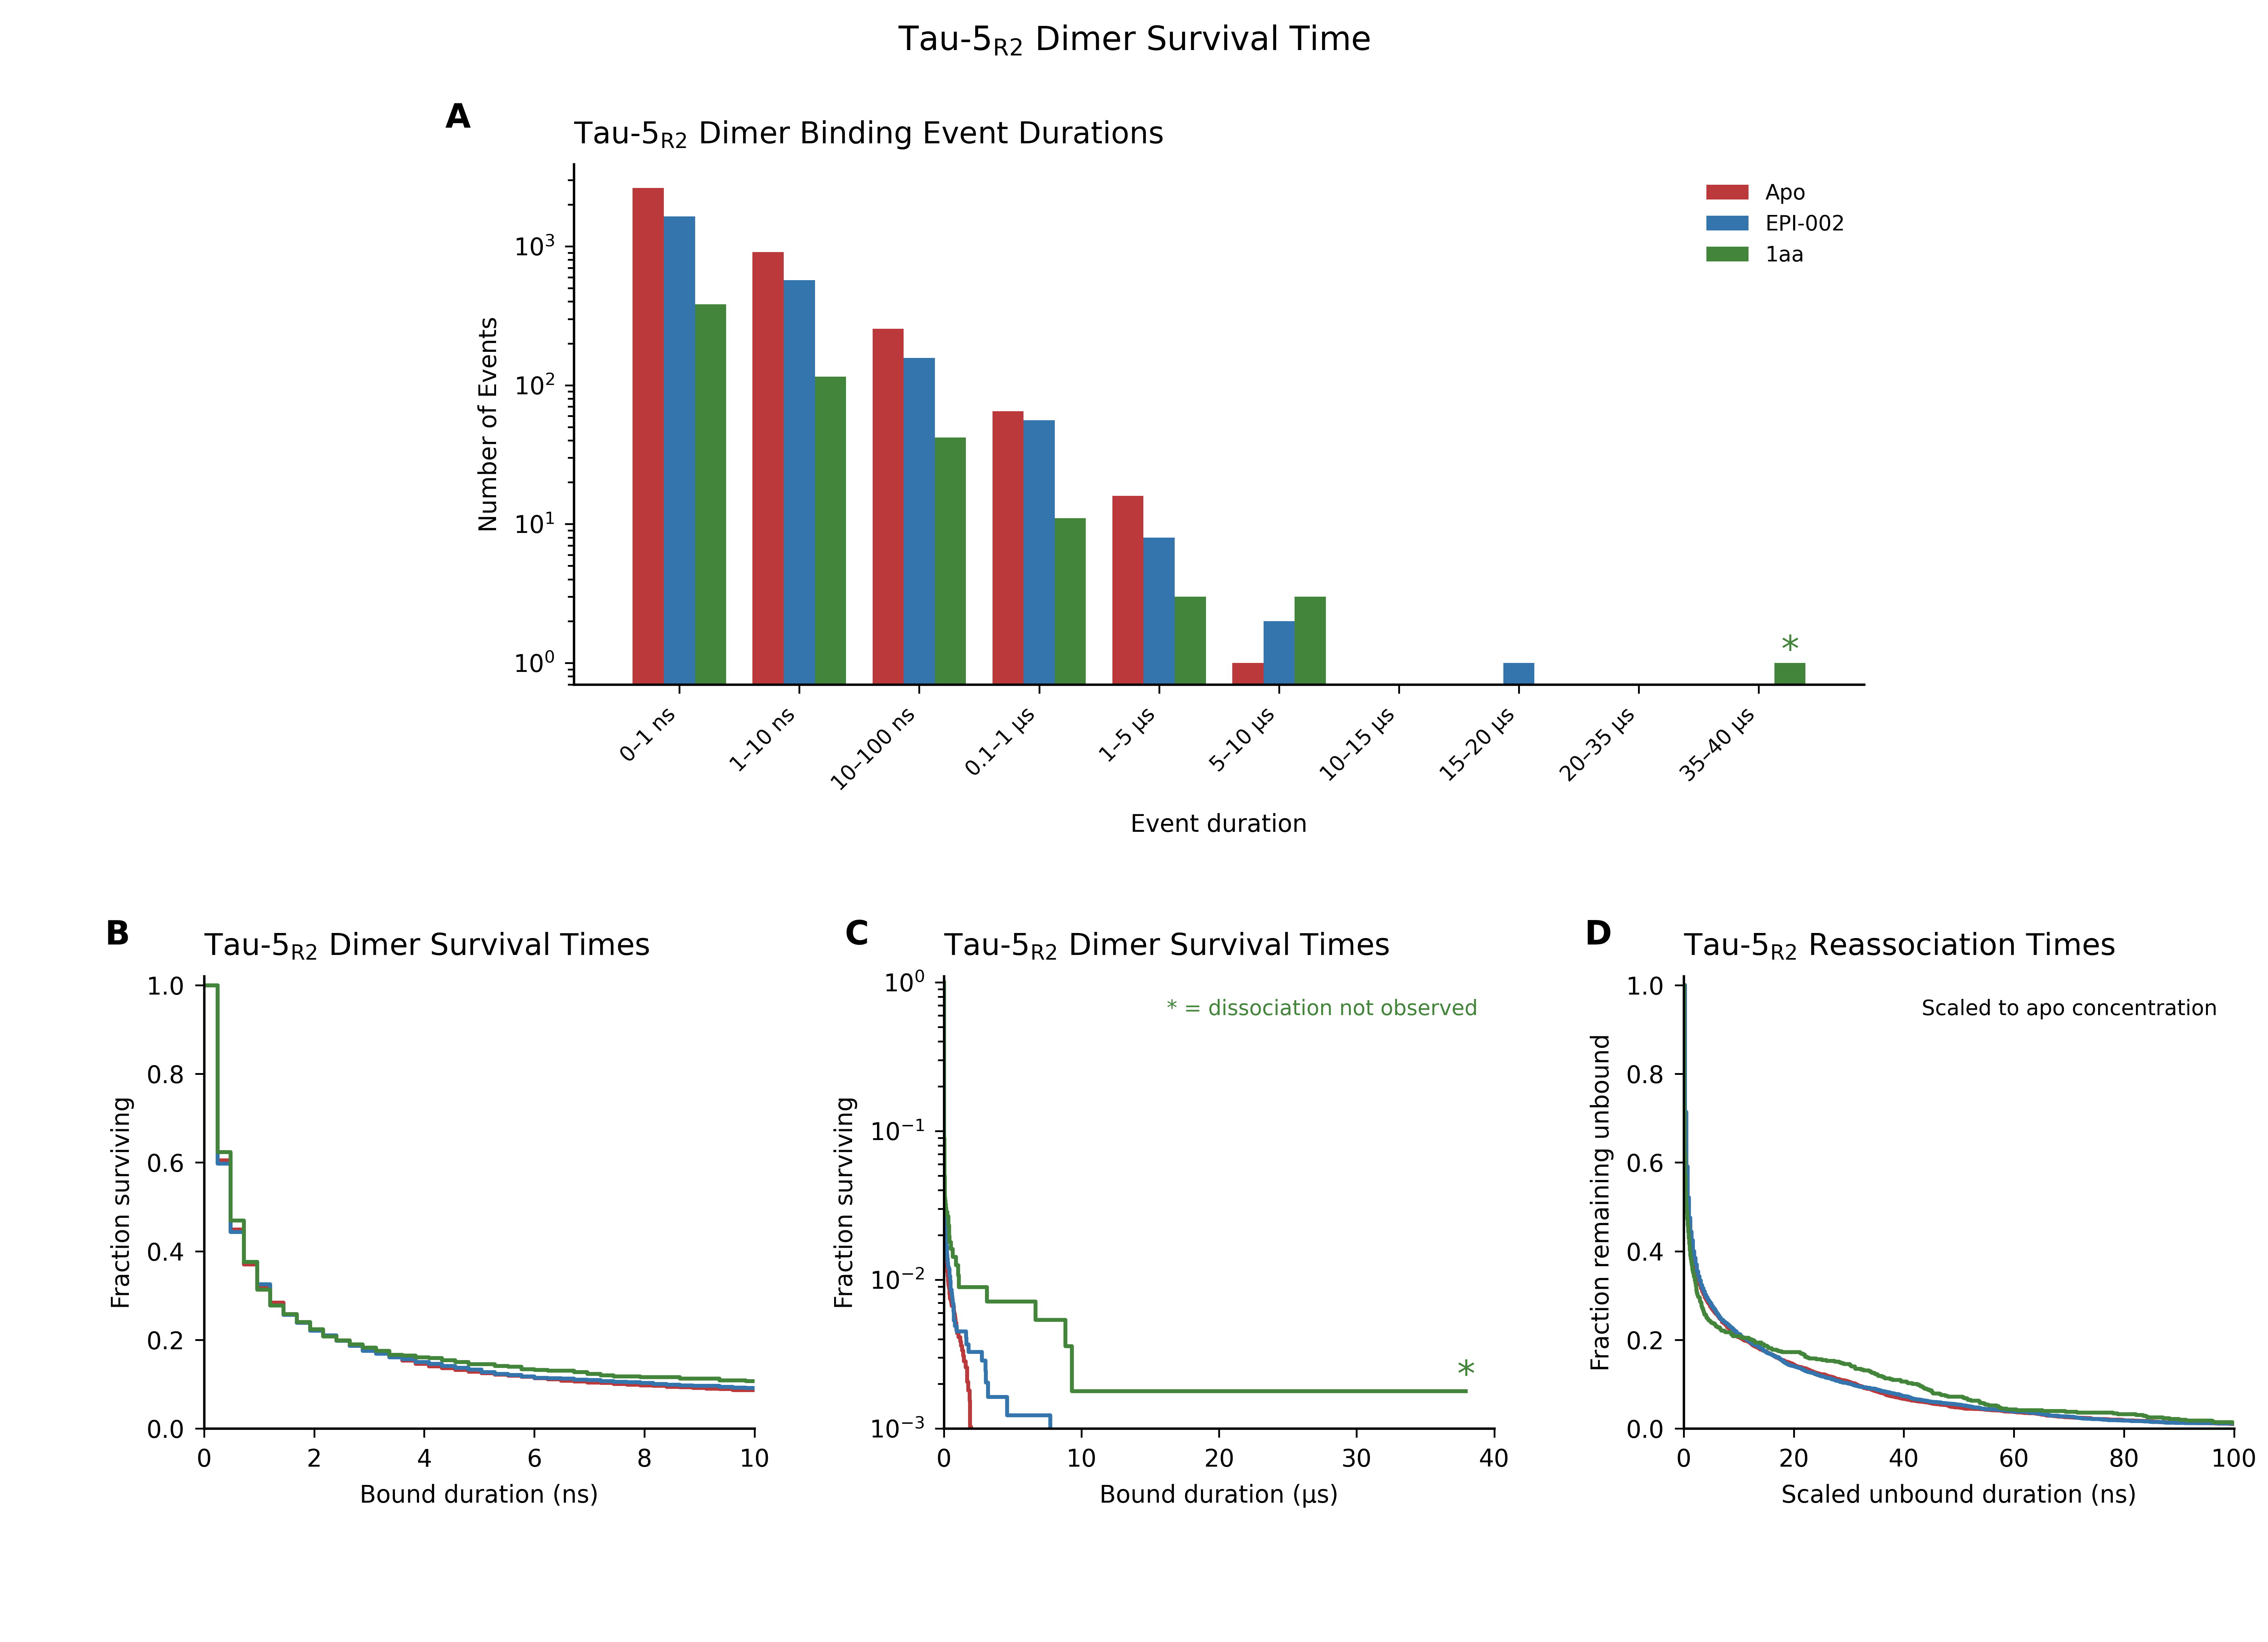

In [ ]:
plt.rcParams.update({"font.family":"DejaVu Sans","mathtext.fontset":"dejavusans","font.size":8,"axes.spines.top":False,
                     "axes.spines.right":False,"pdf.fonttype":42,"ps.fonttype":42,"svg.fonttype":"none"})
fig=plt.figure(figsize=(10.5,7.6),dpi=160)
grid=fig.add_gridspec(2,6,height_ratios=[1.15,1])
ax=[fig.add_subplot(grid[0,1:5])]+[fig.add_subplot(grid[1,j:j+2]) for j in (0,2,4)]
fig.suptitle(r"Tau-5$_{\mathrm{R2}}$ Dimer Survival Time",fontsize=11,y=.985)
titles=[r"Tau-5$_{\mathrm{R2}}$ Dimer Binding Event Durations",
        r"Tau-5$_{\mathrm{R2}}$ Dimer Survival Times",
        r"Tau-5$_{\mathrm{R2}}$ Dimer Survival Times",
        r"Tau-5$_{\mathrm{R2}}$ Reassociation Times"]
# Histogram bins in microseconds: 0–1, 1–10, and 10–100 ns, then microsecond bins.
edge_candidates=np.array([.001,.01,.1,1,5,10,15,20,35,40])
edges=np.r_[0.0,edge_candidates]
max_bound=max(c["bound"]["durations"].max() for c in curves.values())
if max_bound>edges[-1]:edges=np.r_[edges,np.inf]
def edge_label(a,b):
    if np.isinf(b):return f"≥{a:g} µs"
    if b<=.1:return f"{a*1000:g}–{b*1000:g} ns"
    return f"{a:g}–{b:g} µs"
labels=[edge_label(a,b) for a,b in zip(edges[:-1],edges[1:])]
histogram_rows=[]
for i,(name,r) in enumerate(results.items()):
    color=r["config"]["color"];b=curves[name]["bound"]
    counts=np.histogram(b["durations"],edges)[0]
    unfinished=np.histogram(b["durations"][~b["transitions"]],edges)[0]
    assert counts.sum()==len(b["durations"])
    xpos=np.arange(len(counts))+(i-1)*.26
    ax[0].bar(xpos,counts,width=.26,color=color,label=name)
    for j,(count,nc) in enumerate(zip(counts,unfinished)):
        histogram_rows.append(dict(condition=name,lower_us=float(edges[j]),upper_us=float(edges[j+1]),
                                   observed_bound_runs=int(count),dissociation_not_observed=int(nc)))
        if nc:
            ax[0].annotate(r"$*$", xy=(xpos[j],count), xytext=(0,4),
                           textcoords="offset points", ha="center", va="center",
                           color=color, fontsize=12, annotation_clip=True)
    for panel,kind in [(1,"bound"),(2,"bound"),(3,"unbound_normalized")]:
        curve=curves[name][kind]
        scale=1000 if panel in [1,3] else 1
        ax[panel].step(curve["x"]*scale,curve["y"],where="post",color=color,lw=1.3)
        if kind=="bound":
            for t_end in curve["durations"][~curve["transitions"]]:
                value=curve["y"][np.searchsorted(curve["x"],t_end,side="right")-1]
                ax[panel].annotate(r"$*$", xy=(t_end*scale,value), xytext=(0,5),
                                   textcoords="offset points", ha="center", va="center",
                                   color=color, fontsize=12, annotation_clip=True)
for i,a in enumerate(ax):
    a.set_title(titles[i],loc="left",fontsize=10,pad=7)
    a.text(-.10 if i==0 else -.18,1.07,"ABCDEF"[i],transform=a.transAxes,fontweight="bold",fontsize=11)
    a.tick_params(direction="out",length=3,width=.6)
    if i>=1:
        a.set_ylabel("Fraction surviving" if i in [1,2] else "Fraction remaining unbound")
        a.set_ylim(0,1.02)
ax[0].set(yscale="log",ylabel="Number of Events")
ax[0].set_ylim(bottom=.7)
ax[0].set_xticks(np.arange(len(labels)))
ax[0].set_xticklabels(labels,rotation=45,ha="right",fontsize=7)
ax[0].set_xlabel("Event duration", labelpad=6)
ax[0].legend(frameon=False,fontsize=7)
ax[1].set(xscale="linear",xlim=(0,10),xlabel="Bound duration (ns)")
ax[1].set_xticks([0,2,4,6,8,10])
ax[2].set(yscale="log",ylim=(1e-3,1.1),xlim=(0,max(PLOT_BOUND_TAIL_US,max_bound*1.03)),xlabel="Bound duration (µs)")
ax[3].set(xscale="linear",xlim=(0,100),xlabel="Scaled unbound duration (ns)")
ax[3].set_xticks([0,20,40,60,80,100])
ax[3].text(.97,.95,"Scaled to apo concentration",
           transform=ax[3].transAxes,ha="right",va="top",fontsize=7)
fig.subplots_adjust(left=.09,right=.985,bottom=.13,top=.90,wspace=1.05,hspace=.60)
ax[2].text(.97,.95,"* = dissociation not observed",transform=ax[2].transAxes,
           ha="right",va="top",fontsize=7,color=results["1aa"]["config"]["color"])
for extension in ["pdf","svg","png"]:
    fig.savefig(OUTPUT_DIR/f"Figure_S2.{extension}",dpi=600)
save_rows("histogram_counts.csv",histogram_rows)
plt.show()

## Figure caption and saved output files
The caption below is generated from the selected sampling interval and observed unfinished events. No manuscript files are edited. Numerical source data, fit parameters and input settings are saved beside the figure.

In [6]:
unfinished=[]
for name,r in results.items():
    for e in r["events"]:
        if e["state"]=="bound" and not e["transition_observed"]:
            unfinished.append(f"The final {name} dimer remained associated for at least {e['duration_us']:.3f} µs; dissociation was not observed.")
caption=("Supporting Figure S2. Tau-5_R2 Dimer Survival Time. "
         "(A) Histogram of observed bound-event durations; asterisks above bars identify events for which dissociation was not observed. "
         "(B) Fraction of dimer events remaining associated as a function of time since association, over 0–10 ns on a linear time axis. "
         "(C) The same survival distribution on a logarithmic vertical axis. "
         "(D) Fraction of unbound events remaining unbound, shown over 0–100 ns on a linear time axis, after rescaling their durations by their integrated partner concentration relative to the mean apo partner concentration (3.3 mM). "
         "The larger 1aa simulation box gives a lower mean concentration of the single available binding partner (1.3 mM) than in apo and EPI-002 (both 3.3 mM). Assuming association frequency is proportional to partner concentration, this correction scales 1aa waiting times by approximately 0.385 and leaves EPI-002 waiting times nearly unchanged. "
         f"Frames were sampled every {FRAME_INTERVAL_NS:g} ns. "
         f"A bound frame has at least one intermolecular Cα–Cα minimum-image distance below {CONTACT_CUTOFF_NM*10:g} Å. "
         "Continuous events refer to consecutive saved frames; transitions between frames are unresolved. "
         "Initial events with unobserved onset are excluded. Events still ongoing at the endpoint contribute for their observed durations without counting the endpoint as a transition. "
         + " ".join(unfinished))
print(caption)
(OUTPUT_DIR/"Figure_S2_caption.txt").write_text(caption,encoding="utf-8")
settings=dict(frame_interval_ns=FRAME_INTERVAL_NS,contact_cutoff_nm=CONTACT_CUTOFF_NM,
              periodic=PERIODIC,ca_per_monomer=CA_PER_MONOMER,systems=SYSTEMS,
              acf_fit_max_us=ACF_FIT_MAX_US,reference_partner_concentration_M=reference_concentration,
              python=platform.python_version(),
              packages={p:metadata.version(p) for p in ["numpy","scipy","matplotlib","mdtraj"]})
(OUTPUT_DIR/"analysis_settings.json").write_text(json.dumps(settings,indent=2),encoding="utf-8")
print(f"\nSaved Figure_S2.pdf, Figure_S2.svg, Figure_S2.png and numerical source data to {OUTPUT_DIR}.")

Supporting Figure S2. Tau-5_R2 Dimer Survival Time. (A) Histogram of observed bound-event durations; asterisks above bars identify events for which dissociation was not observed. (B) Fraction of dimer events remaining associated as a function of time since association, over 0–10 ns on a linear time axis. (C) The same survival distribution on a logarithmic vertical axis. (D) Fraction of unbound events remaining unbound, shown over 0–100 ns on a linear time axis, after rescaling their durations by their integrated partner concentration relative to the mean apo partner concentration (3.3 mM). The larger 1aa simulation box gives a lower mean concentration of the single available binding partner (1.3 mM) than in apo and EPI-002 (both 3.3 mM). Assuming association frequency is proportional to partner concentration, this correction scales 1aa waiting times by approximately 0.385 and leaves EPI-002 waiting times nearly unchanged. Frames were sampled every 0.24 ns. A bound frame has at least on